# MSAI6320 — Neural Networks
## Unit 6 Lab: Neural Networks with PyTorch

**Course:** MSAI6320 — Natural Language Processing
**Instructor:** Dr. Ahmed I. A. Shawahna | Birzeit University
**Reference:** Jurafsky & Martin (2026), Chapter 6

### Students

| Student ID | Name |
|---|---|
| 1255301 | Rayyan Asia |
| 1255304 | Ameer Eleyan |

---

### Objectives

By the end of this lab you will be able to:

1. Implement neural networks in PyTorch as `nn.Module` classes.
2. Explain the difference between training and evaluation modes, and use `torch.no_grad()` for inference.
3. Organise configurations and experiment results with data classes.
4. Represent a document by mean pooling the pre-trained GloVe embeddings of its words, use it as the input of a feedforward classifier, and compare it with bag-of-words features.
5. Use the embedding matrix $\mathbf{E}$ as a network layer initialized from GloVe, and compare frozen and fine-tuned embeddings.
6. Apply good practices for reproducibility, experiment tracking, and saving and loading models.

### How to use this notebook

- **Run cells in order, one at a time.** Each section depends on the ones above it.
- **Tasks:** look for `# YOUR CODE HERE` and replace the `raise NotImplementedError(...)` line with your code. A cell that needs an unfinished task stops with a message naming that task.
- If you are not familiar with a concept used here, look it up and catch up on it before moving on.

### Outline

| § | Topic | You do |
|---|---|---|
| 0 | Setup | |
| 1 | Typing and object-oriented programming in neural networks | Task 1 |
| 2 | `torch.no_grad()` and train/eval modes | Task 2 |
| 3 | Data classes in Python | |
| 4 | Regularization and activation functions | |
| 5 | Hands-on: text classification with neural networks | |
| 6 | Data preprocessing and feature engineering | |
| 7 | Train/validation/test splits | |
| 8 | Embeddings as input: mean-pooled GloVe vectors | Task 3 |
| 9 | Loss functions and optimization | Tasks 4, 5, 6 |
| 10 | The embedding matrix as a layer | Tasks 7, 8, 9 |
| 11 | Visualizing training progress | Task 10 |
| 12 | Reproducibility and experiment tracking | |
| 13 | Model saving and loading | |
| 14 | Running inference | |

---
## 0. Setup

In [1]:
# ── Setup: run this cell first ────────────────────────────────────────────────

# Install PyTorch and pyarrow (pyarrow reads the dataset file); quick if already installed
!pip install torch pyarrow --quiet

# Import PyTorch for tensor operations and building neural networks
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader

# Dataclasses and typing help structure data neatly and clearly
from dataclasses import dataclass
from typing import Callable, List, Tuple, Dict, Optional, Union

# Importing libraries for data manipulation and visualization
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# Importing libraries for data loading and preprocessing
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
import copy
import json
import random
import os
import re
from datetime import datetime

# Set a random seed for reproducibility
def set_seed(seed: int = 42) -> None:
    """Set seed for reproducibility."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed()


def require(*names: str, task: int) -> None:
    """Stop with a clear message when a variable created by an unfinished task is still missing."""
    missing = [name for name in names if globals().get(name) is None]
    if missing:
        raise RuntimeError(f"Task {task} is not finished yet ({', '.join(missing)} not defined). "
                           "Complete it, re-run its cell, then re-run this cell.")


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip


---
## 1. Typing and Object-Oriented Programming (OOP) in Neural Networks

Clean code structure, typing, and  Object-Oriented Programming (OOP) principles enhance maintainability, readability, and reusability, especially critical for large-scale ML projects.
In this section, we'll create a basic neural network using object-oriented programming principles.

### Building a Simple Neural Network

A neural network consists of layers performing linear transformations and non-linear activations. Each layer applies transformations to the input data.

**Example:**  Here, we define a simple feedforward neural network with hidden layers and dropout.

In [2]:
class SimpleNN(nn.Module):
    """A simple neural network with configurable architecture."""

    def __init__(self, input_size: int, hidden_size: int, output_size: int, dropout_rate: float = 0.2):
        """
        Initialize the neural network.

        Args:
            input_size: Number of input features (d in the slides)
            hidden_size: Number of neurons in hidden layer (d_h)
            output_size: Number of output classes (K)
            dropout_rate: Dropout probability for regularization
        """
        super(SimpleNN, self).__init__()
        self.W = nn.Linear(input_size, hidden_size)
        self.dropout = nn.Dropout(dropout_rate)
        self.U = nn.Linear(hidden_size, output_size)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """
        Forward pass through the network.

        Args:
            x: Input tensor of shape [batch_size, input_size]

        Returns:
            Output tensor of shape [batch_size, output_size]
        """
        h = F.relu(self.W(x))   # hidden layer h
        h = self.dropout(h)
        z = self.U(h)           # scores z (logits)
        return z

    def predict(self, x: torch.Tensor) -> torch.Tensor:
        """
        Make predictions using the model.

        Args:
            x: Input tensor

        Returns:
            Predicted class indices
        """
        self.eval()  # predictions must not use dropout (see §2)
        with torch.no_grad():
            outputs = self.forward(x)
            _, predicted = torch.max(outputs.data, 1)
        return predicted

The `SimpleNN` class demonstrates how to inherit from PyTorch's `nn.Module`. We then initialize layers in the `__init__` function and implement a forward pass to pass data through the network. We can also add further utility methods like `predict`to make predicitions based on the model outputs.


This pattern of encapsulating model logic in a class will be used throughout your work with neural networks.

**Notation.** `W` holds $\mathbf{W}$ and $\mathbf{b}$, its ReLU output is the hidden layer $\mathbf{h}$, and `U` maps $\mathbf{h}$ to the scores $\mathbf{z}$ (PyTorch calls them *logits*); softmax turns $\mathbf{z}$ into $\hat{\mathbf{y}}$. `nn.Linear` stores its weight as [out × in] and computes $\mathbf{X}\mathbf{W}^\top+\mathbf{b}$, the batched form in the slides.

In [3]:
# ── Let's create an instance of our model ─────────────────────────────────────
set_seed()
input_size = 10
hidden_size = 20
output_size = 2
model = SimpleNN(input_size, hidden_size, output_size)
print(f"Model architecture:\n{model}")

# Example forward pass
example_input = torch.randn(5, input_size) # Batch of 5 samples
output = model(example_input) # Forward pass
prediction = model.predict(example_input) # Prediction
print(f"\nExample input shape: {example_input.shape}")
print(f"Example output shape: {output.shape}")
print(f"Example output:\n{output}")
print(f"Predicted classes:\n{prediction}")

Model architecture:
SimpleNN(
  (W): Linear(in_features=10, out_features=20, bias=True)
  (dropout): Dropout(p=0.2, inplace=False)
  (U): Linear(in_features=20, out_features=2, bias=True)
)

Example input shape: torch.Size([5, 10])
Example output shape: torch.Size([5, 2])
Example output:
tensor([[-0.1326, -0.3764],
        [-0.1143, -0.8384],
        [ 0.0054, -0.1468],
        [ 0.1878, -0.3758],
        [-0.3437, -0.1233]], grad_fn=<AddmmBackward0>)
Predicted classes:
tensor([1, 0, 0, 0, 1])


### Task 1 — Implement a deeper neural network with multiple hidden layers

**Task:** For this exercise, create a new class called `DeepNN` that extends nn.Module. Your implementation should include:
* 3 hidden layers with configurable sizes
* ReLU activations between layers
* Dropout for regularization
* `__init__` and `forward` methods

In [4]:
class DeepNN(nn.Module):
    """A feedforward network with 3 hidden layers of configurable sizes, ReLU activations and dropout."""

    def __init__(self, input_size: int, hidden_sizes: List[int], output_size: int, dropout_rate: float = 0.2):
        super().__init__()

        if len(hidden_sizes) != 3:
            raise ValueError("hidden_sizes must contain exactly 3 integers.")

        # Define the layers
        self.fc1 = nn.Linear(input_size, hidden_sizes[0])
        self.fc2 = nn.Linear(hidden_sizes[0], hidden_sizes[1])
        self.fc3 = nn.Linear(hidden_sizes[1], hidden_sizes[2])
        self.out = nn.Linear(hidden_sizes[2], output_size)

        # Define dropout
        self.dropout = nn.Dropout(dropout_rate)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # First hidden layer
        x = F.relu(self.fc1(x))
        x = self.dropout(x)

        # Second hidden layer
        x = F.relu(self.fc2(x))
        x = self.dropout(x)

        # Third hidden layer
        x = F.relu(self.fc3(x))
        x = self.dropout(x)

        # Output layer (no activation or dropout, directly returning logits)
        return self.out(x)

In [5]:
# Test Task 1: DeepNN
print("--- Testing Task 1: DeepNN ---")
try:
    # Initialize with input_size=10, 3 hidden layers, output_size=2
    test_deep_model = DeepNN(input_size=10, hidden_sizes=[20, 15, 10], output_size=2)
    print("Successfully initialized DeepNN!")

    # Test forward pass with batch of 5
    test_x = torch.randn(5, 10)
    test_out = test_deep_model(test_x)
    print(f"Forward pass successful! Input shape: {test_x.shape} -> Output shape: {test_out.shape}")
    assert test_out.shape == (5, 2), f"Expected output shape (5, 2), got {test_out.shape}"
    print("Task 1 Test: PASSED ✅")
except Exception as e:
    print(f"Task 1 Test: FAILED ❌\nError: {e}")

--- Testing Task 1: DeepNN ---
Successfully initialized DeepNN!
Forward pass successful! Input shape: torch.Size([5, 10]) -> Output shape: torch.Size([5, 2])
Task 1 Test: PASSED ✅


---
## 2. Understanding torch.no_grad() and Train/Eval Modes

Gradients represent how much each parameter affects the final prediction, guiding parameter updates during training.
Managing gradients efficiently is vital for training neural networks and optimizing inference.

For efficient and correct model development, it's crucial to understand PyTorch's execution modes.
PyTorch models have two primary operating modes: training and evaluation. These modes control how certain layers behave and whether gradients are computed.

- `.eval()` sets the model to evaluation mode.
- `torch.no_grad()` disables gradient calculation, saving memory during inference.

In [6]:
# ── Let's demonstrate different behaviors in train and eval modes ─────────────
set_seed()
model = SimpleNN(input_size, hidden_size, output_size)
input_data = torch.randn(5, input_size)

# Training mode (default)
model.train()
print("Training mode (model.train()):")
print("-" * 30)

# Forward pass with gradients
output_train = model(input_data)
print(f"Output shape: {output_train.shape}")
print(f"Requires gradient: {output_train.requires_grad}")

# Make another pass, observe dropout
output_train2 = model(input_data)
diff_train = torch.sum(torch.abs(output_train - output_train2)).item()
print(f"Difference between two forward passes: {diff_train:.6f} (due to dropout)")

# Evaluation mode
model.eval()
print("\nEvaluation mode (model.eval()):")
print("-" * 30)

# Forward pass in eval mode
output_eval = model(input_data)
print(f"Output shape: {output_eval.shape}")
print(f"Requires gradient: {output_eval.requires_grad}")

# Make another pass, observe no dropout
output_eval2 = model(input_data)
diff_eval = torch.sum(torch.abs(output_eval - output_eval2)).item()
print(f"Difference between two forward passes: {diff_eval:.6f} (should be 0, no dropout)")

# Using torch.no_grad()
print("\nUsing torch.no_grad():")
print("-" * 30)
with torch.no_grad():
    output_no_grad = model(input_data)
    print(f"Output shape: {output_no_grad.shape}")
    print(f"Requires gradient: {output_no_grad.requires_grad}")

Training mode (model.train()):
------------------------------
Output shape: torch.Size([5, 2])
Requires gradient: True
Difference between two forward passes: 0.996750 (due to dropout)

Evaluation mode (model.eval()):
------------------------------
Output shape: torch.Size([5, 2])
Requires gradient: True
Difference between two forward passes: 0.000000 (should be 0, no dropout)

Using torch.no_grad():
------------------------------
Output shape: torch.Size([5, 2])
Requires gradient: False


**Dropout Behavior in Different Modes**
Dropout is a regularization technique that randomly sets a portion of neurons to zero during training to prevent overfitting. However, this random behavior would be problematic during inference:

* In training mode (`model.train()`): Dropout randomly deactivates neurons based on the dropout probability.Each forward pass produces slightly different results due to this randomness. This intentional noise helps the model generalize better.
* In evaluation mode (`model.eval()`): Dropout is effectively disabled (all neurons are active). Output is deterministic (same input always produces same output). No randomness is introduced to prediction.

This difference is why `model.eval()` must be called before making predictions on new data to ensure consistent results

### Task 2 — Comparing memory usage with and without gradients

Training neural networks requires computing gradients for parameter updates. This process:
* Stores intermediate activations in memory for backpropagation
* Creates a computational graph that tracks operations
* Significantly increases memory usage as model size grows

When performing inference (making predictions), we don't need these gradients. Using `torch.no_grad()`:
* Disables gradient calculation
* Reduces memory usage by not storing intermediate activations
* Speeds up computation by not building the computational graph
* Prevents accidental parameter updates

**Task:** Implement a function that measures and compares memory usage when processing a large batch with and without gradient calculation. When would you use which mode?

In [7]:
# Task 2: Create a function that measures and compares the memory usage
# when processing a large batch with and without gradients
import tracemalloc

batch = torch.randn(10000, input_size)  # Large batch

def compare_memory(model: nn.Module, batch: torch.Tensor) -> Dict[str, int]:
    """Return the memory (in bytes) used by one forward pass of batch, with and without gradient calculation."""
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats()
        base_mem = torch.cuda.memory_allocated()
        _ = model(batch)
        mem_with = torch.cuda.max_memory_allocated() - base_mem

        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats()
        base_mem = torch.cuda.memory_allocated()
        with torch.no_grad():
            _ = model(batch)
        mem_without = torch.cuda.max_memory_allocated() - base_mem

        return {"with_gradients": mem_with, "without_gradients": mem_without}
    else:
        # Fallback for CPU memory tracking using tracemalloc
        tracemalloc.start()
        _ = model(batch)
        _, peak_with = tracemalloc.get_traced_memory()
        tracemalloc.stop()

        tracemalloc.start()
        with torch.no_grad():
            _ = model(batch)
        _, peak_without = tracemalloc.get_traced_memory()
        tracemalloc.stop()

        return {"with_gradients": peak_with, "without_gradients": peak_without}


In [8]:
# Test Task 2: compare_memory
print("--- Testing Task 2: compare_memory ---")
try:
    # Create a small dummy model and batch for testing the function structure
    test_model = SimpleNN(input_size=10, hidden_size=20, output_size=2)
    test_batch = torch.randn(100, 10)
    mem_results = compare_memory(test_model, test_batch)
    print(f"Memory measurements result: {mem_results}")
    assert isinstance(mem_results, dict), "Result must be a dictionary"
    assert "with_gradients" in mem_results and "without_gradients" in mem_results, "Result must contain keys 'with_gradients' and 'without_gradients'"
    print("Task 2 Test: PASSED ✅")
except Exception as e:
    print(f"Task 2 Test: FAILED ❌\nError: {e}")

--- Testing Task 2: compare_memory ---
Memory measurements result: {'with_gradients': 1385, 'without_gradients': 1171}
Task 2 Test: PASSED ✅


**Your answer — Task 2:**
Basically, we compute gradients during training so we can update the weights using backpropagation. But when we evaluate or test the model (inference), we use `torch.no_grad()` because we don't need to update weights anymore. This saves a ton of memory and makes everything run way faster.

---
## 3. Data Classes in Python

Using dataclasses streamlines hyperparameter management, making experiments reproducible and organized. Hyperparameters are settings chosen before training that influence model learning. Hyperparameters like learning rate, batch size, and epochs affect how the model learns and performs.

Data classes provide a clean way to organize configuration and results in your machine learning projects. This section introduces Python's dataclass decorator and demonstrates how to use it effectively.

In [9]:
@dataclass
class TrainingConfig:
    """Data class for neural network training configuration."""
    learning_rate: float = 0.001
    batch_size: int = 32
    epochs: int = 10
    weight_decay: float = 0.0001
    early_stopping_patience: int = 3
    device: str = "cuda" if torch.cuda.is_available() else "cpu"

    def __post_init__(self):
        """Validate configuration after initialization."""
        if self.learning_rate <= 0:
            raise ValueError("Learning rate must be positive")
        if self.batch_size <= 0:
            raise ValueError("Batch size must be positive")
        if self.early_stopping_patience < 0:
            raise ValueError("Patience must be non-negative")

    def to_dict(self) -> Dict:
        """Convert config to dictionary."""
        return {
            "learning_rate": self.learning_rate,
            "batch_size": self.batch_size,
            "epochs": self.epochs,
            "weight_decay": self.weight_decay,
            "early_stopping_patience": self.early_stopping_patience,
            "device": self.device
        }

The `TrainingConfig`class shows how to define default values for configuration parameters. We can validate configurations with `__post_init__`, and add a method for converting configurations to other formats.

In [10]:
# ── Create and use a configuration ────────────────────────────────────────────
config = TrainingConfig(learning_rate=0.01, epochs=20)
print(f"Training configuration:\n{config}")

# Modify and validate configurations
try:
    invalid_config = TrainingConfig(learning_rate=-0.1)
except ValueError as e:
    print(f"Validation works: {e}")

Training configuration:
TrainingConfig(learning_rate=0.01, batch_size=32, epochs=20, weight_decay=0.0001, early_stopping_patience=3, device='cpu')
Validation works: Learning rate must be positive


---
## 4. Advanced NN Concepts: Regularization and Activation Functions

As models grow in complexity, understanding regularization techniques and activation functions becomes crucial for achieving good performance. This section introduces advanced neural network concepts that will improve your models.

In [11]:
class AdvancedNN(nn.Module):
    """Neural network with various regularization techniques and activation functions.

    In the slides' notation, layer l holds W^[l] and b^[l].
    """

    def __init__(
        self,
        input_size: int,
        hidden_sizes: List[int],
        output_size: int,
        dropout_rate: float = 0.2,
        activation: str = "relu",
        use_batch_norm: bool = True,
        weight_constraint: Optional[float] = None
    ):
        """
        Initialize the advanced neural network.

        Args:
            input_size: Number of input features (d)
            hidden_sizes: List of hidden layer sizes
            output_size: Number of output classes (K)
            dropout_rate: Dropout probability
            activation: Activation function name ('sigmoid', 'tanh', 'relu', 'leaky_relu', 'silu', 'gelu')
            use_batch_norm: Whether to use batch normalization
            weight_constraint: Maximum norm for weight constraint (L2 norm)
        """
        super(AdvancedNN, self).__init__()

        self.layers = nn.ModuleList()
        self.batch_norms = nn.ModuleList()
        self.dropouts = nn.ModuleList()
        self.weight_constraint = weight_constraint

        # Input layer
        self.layers.append(nn.Linear(input_size, hidden_sizes[0]))
        if use_batch_norm:
            self.batch_norms.append(nn.BatchNorm1d(hidden_sizes[0]))
        self.dropouts.append(nn.Dropout(dropout_rate))

        # Hidden layers
        for i in range(len(hidden_sizes) - 1):
            self.layers.append(nn.Linear(hidden_sizes[i], hidden_sizes[i+1]))
            if use_batch_norm:
                self.batch_norms.append(nn.BatchNorm1d(hidden_sizes[i+1]))
            self.dropouts.append(nn.Dropout(dropout_rate))

        # Output layer (no batch norm, activation or dropout)
        self.layers.append(nn.Linear(hidden_sizes[-1], output_size))

        # Activation function
        if activation == "sigmoid":
            self.activation = torch.sigmoid
        elif activation == "tanh":
            self.activation = torch.tanh
        elif activation == "relu":
            self.activation = F.relu
        elif activation == "leaky_relu":
            self.activation = F.leaky_relu
        elif activation == "silu":
            self.activation = F.silu
        elif activation == "gelu":
            self.activation = F.gelu
        else:
            raise ValueError(f"Unsupported activation function: {activation}")

        # Flag for batch normalization
        self.use_batch_norm = use_batch_norm

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """Forward pass through the network."""
        # Apply each layer with activation, batch norm, and dropout
        for i in range(len(self.layers) - 1):
            x = self.layers[i](x)
            if self.use_batch_norm:
                x = self.batch_norms[i](x)  # in training mode, batch norm needs more than one example per batch
            x = self.activation(x)
            x = self.dropouts[i](x)

        # Output layer (no activation or dropout)
        x = self.layers[-1](x)
        return x

    def apply_weight_constraint(self) -> None:
        """Rescale each row of every weight matrix to an L2 norm of at most weight_constraint.

        Call this after optimizer.step(), not inside forward.
        """
        if self.weight_constraint is None:
            return
        with torch.no_grad():
            for layer in self.layers:
                norm = torch.norm(layer.weight, 2, dim=1, keepdim=True)
                desired = torch.clamp(norm, 0, self.weight_constraint)
                layer.weight.mul_(desired / (1e-7 + norm))

# Create a simple test for our advanced model
set_seed()
hidden_sizes = [32, 16]
advanced_model = AdvancedNN(
    input_size=10,
    hidden_sizes=hidden_sizes,
    output_size=2,
    activation="gelu",
    weight_constraint=3.0
)

print(f"Advanced model architecture:\n{advanced_model}")

# Test forward pass
test_input = torch.randn(8, input_size)
test_output = advanced_model(test_input)
print(f"\nTest input shape: {test_input.shape}")
print(f"Test output shape: {test_output.shape}")

Advanced model architecture:
AdvancedNN(
  (layers): ModuleList(
    (0): Linear(in_features=10, out_features=32, bias=True)
    (1): Linear(in_features=32, out_features=16, bias=True)
    (2): Linear(in_features=16, out_features=2, bias=True)
  )
  (batch_norms): ModuleList(
    (0): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (1): BatchNorm1d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  )
  (dropouts): ModuleList(
    (0-1): 2 x Dropout(p=0.2, inplace=False)
  )
)

Test input shape: torch.Size([8, 10])
Test output shape: torch.Size([8, 2])


With this class, we added different activation functions (sigmoid, tanh, ReLU, Leaky ReLU, SiLU, GELU), and regularization techniques (dropout, batch normalization, weight constraints).

---
## 5. Hands-On: Text Classification with Neural Networks

In this part, we'll apply the concepts from the sections above to a practical text classification task. We'll build a sentiment analyzer for movie reviews, taking you through the entire machine learning workflow from data preprocessing to model evaluation.
We will use a dataset from the Internet (from the model & dataset database [Huggingface](https://huggingface.co/datasets/stanfordnlp/imdb)).

In [12]:
# ── Load the IMDB reviews ─────────────────────────────────────────────────────

print("\nLoading and preprocessing example text data...")

DATA_FILE = os.path.join("data", "imdb_sample.csv")
if not os.path.exists(DATA_FILE):
    # Download once from Hugging Face (needs internet and pyarrow), then keep a local copy.
    url = "https://huggingface.co/datasets/stanfordnlp/imdb/resolve/main/plain_text/train-00000-of-00001.parquet"
    os.makedirs("data", exist_ok=True)
    pd.read_parquet(url).sample(5000, random_state=42).to_csv(DATA_FILE, index=False)
df = pd.read_csv(DATA_FILE)

# The reviews contain HTML line breaks "<br />"; remove them so that "br" is not treated as a word.
df["text"] = df["text"].str.replace("<br />", " ", regex=False)

reviews = df['text'].tolist()
labels = df['label'].tolist()

print(f"Loaded {len(reviews)} training samples and {len(labels)} labels.")
print(f"Sample text: {reviews[0]}")
print(f"Sample label: {labels[0]}")


Loading and preprocessing example text data...
Loaded 5000 training samples and 5000 labels.
Sample text: Dumb is as dumb does, in this thoroughly uninteresting, supposed black comedy. Essentially what starts out as Chris Klein trying to maintain a low profile, eventually morphs into an uninspired version of "The Three Amigos", only without any laughs. In order for black comedy to work, it must be outrageous, which "Play Dead" is not. In order for black comedy to work, it cannot be mean spirited, which "Play Dead" is. What "Play Dead" really is, is a town full of nut jobs. Fred Dunst does however do a pretty fair imitation of Billy Bob Thornton's character from "A Simple Plan", while Jake Busey does a pretty fair imitation of, well, Jake Busey. - MERK
Sample label: 0


[StanfordNLP/imdb](https://huggingface.co/datasets/stanfordnlp/imdb) is a large movie review dataset. It is used for binary sentiment classification. It provides 50,000 highly polar movie reviews (of which we randomly sample 5,000). A label "0" corresponds to a negative sentiment, "1" symbolizes positive sentiment.

---
## 6. Data Preprocessing and Feature Engineering

Before training any neural network, proper data preprocessing is essential. This section demonstrates how to prepare text data for a classification task.

In [13]:
@dataclass
class TextDataset:
    """Dataset class for text classification."""
    texts: List[str]
    labels: List[int]
    vectorizer: Optional[CountVectorizer] = None
    is_fitted: bool = False

    def preprocess(self, max_features: int = 1000) -> None:
        """
        Preprocess the text data by vectorizing it.

        Args:
            max_features: Maximum number of features (vocabulary size)
        """
        if not self.vectorizer:
            self.vectorizer = CountVectorizer(max_features=max_features)
            self.vectorizer.fit(self.texts)
            self.is_fitted = True

    def get_features(self) -> np.ndarray:
        """Convert texts to feature vectors."""
        if not self.is_fitted:
            raise ValueError("Dataset has not been preprocessed. Call preprocess() first.")
        return self.vectorizer.transform(self.texts).toarray()

    def get_tensor_dataset(self) -> Tuple[torch.Tensor, torch.Tensor]:
        """Get PyTorch tensors for features and labels."""
        features = self.get_features()
        return (
            torch.tensor(features, dtype=torch.float32),
            torch.tensor(self.labels, dtype=torch.long)
        )

    def get_vocabulary_size(self) -> int:
        """Get the size of the vocabulary."""
        if not self.is_fitted:
            raise ValueError("Dataset has not been preprocessed. Call preprocess() first.")
        return len(self.vectorizer.get_feature_names_out())

    def transform_new_texts(self, texts: List[str]) -> np.ndarray:
        """Transform new texts using the fitted vectorizer."""
        if not self.is_fitted:
            raise ValueError("Dataset has not been preprocessed. Call preprocess() first.")
        return self.vectorizer.transform(texts).toarray()


# Create our dataset. The vocabulary is fitted in §7, on the training split only.
dataset = TextDataset(reviews, labels)
print(f"Dataset: {len(dataset.texts)} reviews")

Dataset: 5000 reviews


The `TextDataset` class encapsulates dataset operations in a reusable class. As we cannot work with the reviews in their string format right away, we transform them to numeric vectors using `CountVectorizer`. We convert the raw data into PyTorch tensors.

---
## 7. Train/Validation/Test Splits

Properly splitting your data is crucial for reliable model evaluation. This section covers how to create train, validation, and test sets while maintaining consistent preprocessing.

In [14]:
def split_dataset(
    dataset: TextDataset,
    val_size: float = 0.15,
    test_size: float = 0.15,
    random_state: int = 42
) -> Tuple[TextDataset, TextDataset, TextDataset]:
    """
    Split a dataset into train, validation, and test sets.

    Args:
        dataset: The original dataset
        val_size: Proportion for validation
        test_size: Proportion for testing
        random_state: Random seed for reproducibility

    Returns:
        Tuple of (train_dataset, val_dataset, test_dataset)
    """
    # First split into train+val and test
    texts_train_val, texts_test, labels_train_val, labels_test = train_test_split(
        dataset.texts, dataset.labels, test_size=test_size, random_state=random_state,
        stratify=dataset.labels
    )

    # Then split train+val into train and val
    adjusted_val_size = val_size / (1 - test_size)
    texts_train, texts_val, labels_train, labels_val = train_test_split(
        texts_train_val, labels_train_val, test_size=adjusted_val_size, random_state=random_state,
        stratify=labels_train_val
    )

    # Create one dataset per split (the vocabulary is fitted afterwards, on train only)
    train_dataset = TextDataset(texts_train, labels_train)
    val_dataset = TextDataset(texts_val, labels_val)
    test_dataset = TextDataset(texts_test, labels_test)

    return train_dataset, val_dataset, test_dataset

# Split our dataset
train_dataset, val_dataset, test_dataset = split_dataset(dataset)

# Fit the vocabulary on the training texts only, then share it with the validation and test sets
train_dataset.preprocess(max_features=100)  # Limit features for the example
for part in (val_dataset, test_dataset):
    part.vectorizer, part.is_fitted = train_dataset.vectorizer, True

print(f"Vocabulary size: {train_dataset.get_vocabulary_size()}")
print(f"\nSample text: '{train_dataset.texts[0]}'")
print(f"Vectorized (first 10 features): {train_dataset.get_features()[0][:10]}...")

# Create PyTorch tensors
X_train, y_train = train_dataset.get_tensor_dataset()
X_val, y_val = val_dataset.get_tensor_dataset()
X_test, y_test = test_dataset.get_tensor_dataset()

print(f"\nTraining set: {len(train_dataset.texts)} examples")
print(f"Validation set: {len(val_dataset.texts)} examples")
print(f"Test set: {len(test_dataset.texts)} examples")
print(f"\nFeature tensor shapes:")
print(f"X_train: {X_train.shape}, y_train: {y_train.shape}")
print(f"X_val: {X_val.shape}, y_val: {y_val.shape}")
print(f"X_test: {X_test.shape}, y_test: {y_test.shape}")

Vocabulary size: 100

Sample text: 'Despite having known people who are either great fans of Noam Chomsky, or think he's a tired relic from the 1960s, I really had no opinion of the man, save that I knew he gained fame as a linguist, although I could not elucidate any of his theories, and that he was a liberal socialist with Marxist leanings. So, stumbling across the DVD of the 2003 documentary Noam Chomsky: Rebel Without A Pause, in a used video store, a film which followed him on a 2002 book tour for his book 9-11, I decided to get it, just so I could have a little bit of knowledge about the man the next time a person, pro or con, spoke of him. While glad I got the film, my initial reaction to this dull and ill edited hagiography was, so what's all the fuss about?  For a man with so many degrees, lauded as 'the most important intellectual alive', by the New York Times, according to the DVD's case, there sure was not a lot there, intellectually speaking. I know I would chew him up and

Vectorized (first 10 features): [ 6  0  5  1  2 27  2  7 10  3]...



Training set: 3500 examples
Validation set: 750 examples
Test set: 750 examples

Feature tensor shapes:
X_train: torch.Size([3500, 100]), y_train: torch.Size([3500])
X_val: torch.Size([750, 100]), y_val: torch.Size([750])
X_test: torch.Size([750, 100]), y_test: torch.Size([750])


We performed stratified splitting based on the labels of our data. We calculate appropriate split proportions first, and then create dataset objects for each split. The vocabulary is fitted on the training split only and shared with the other two.

---
## 8. Embeddings as Input: Mean-Pooled GloVe Vectors

Instead of hand-built count features, we represent each review by the mean of the pre-trained GloVe vectors of its words. We use the same `glove-wiki-gigaword-100` model and the same cleaning and tokenization as `get_phrase_embedding` in the Embedding lab. Words that are not in GloVe are skipped, and a review with no known word gets a zero vector.

$$\mathbf{x}=\text{mean}(\mathbf{e}(w_1),\dots,\mathbf{e}(w_n))\qquad\mathbf{h}=\sigma(\mathbf{x}\mathbf{W}+\mathbf{b})\qquad\mathbf{z}=\mathbf{h}\mathbf{U}\qquad\hat{\mathbf{y}}=\text{softmax}(\mathbf{z})$$

In [15]:
# ── Load GloVe, as in the Embedding lab ───────────────────────────────────────

!pip install gensim --quiet

import gensim.downloader as api
from nltk.tokenize import WordPunctTokenizer

print("Loading pre-trained GloVe embeddings (glove-wiki-gigaword-100)...")
print("This may take a few minutes on the first run (downloading ~128 MB)...\n")

# Called `model` in the Embedding lab; here `model` is our neural network, so we call it `glove`.
glove = api.load('glove-wiki-gigaword-100')
print(f"Vocabulary size: {len(glove.key_to_index):,} words, vector dimension: {glove.vector_size}")

tokenizer = WordPunctTokenizer()


def clean_tokens(text: str) -> List[str]:
    """The cleaning and tokenization of get_phrase_embedding: keep letters only, lowercase, tokenize."""
    return tokenizer.tokenize(re.sub(r"[^a-zA-Z ]", " ", text).lower())


print(clean_tokens("I'm very sure. This never happened to me before..."))


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip


Loading pre-trained GloVe embeddings (glove-wiki-gigaword-100)...
This may take a few minutes on the first run (downloading ~128 MB)...



Vocabulary size: 400,000 words, vector dimension: 100
['i', 'm', 'very', 'sure', 'this', 'never', 'happened', 'to', 'me', 'before']


### Task 3 — Mean pooling of GloVe embeddings

**Task:** Complete `embed_corpus` so that it returns one row per text: the mean of the GloVe vectors of the text's tokens (use `clean_tokens`), skipping tokens that are not in `glove`, and a zero vector when no token is found. Return a `float32` tensor of shape [m × d].

In [16]:
def embed_corpus(texts: List[str]) -> torch.Tensor:
    """Mean-pool the GloVe vectors of each text. Returns a float32 tensor of shape [len(texts) × glove.vector_size]."""
    dim = glove.vector_size
    results = []
    for text in texts:
        tokens = clean_tokens(text)
        vectors = [glove[t] for t in tokens if t in glove]
        if vectors:
            results.append(np.mean(vectors, axis=0))
        else:
            results.append(np.zeros(dim, dtype=np.float32))
    return torch.tensor(np.array(results), dtype=torch.float32)


In [17]:
# Test Task 3: embed_corpus
print("--- Testing Task 3: embed_corpus ---")
try:
    sample_texts = ["I love this movie", "An absolutely terrible film", ""]
    embeddings = embed_corpus(sample_texts)
    print(f"Embeddings shape: {embeddings.shape}")
    assert embeddings.shape == (3, 100), f"Expected shape (3, 100), got {embeddings.shape}"
    assert torch.all(embeddings[2] == 0), "An empty/unknown word text should yield a zero vector!"
    print("Task 3 Test: PASSED ✅")
except Exception as e:
    print(f"Task 3 Test: FAILED ❌\nError: {e}")

--- Testing Task 3: embed_corpus ---
Embeddings shape: torch.Size([3, 100])
Task 3 Test: PASSED ✅


In [18]:
# ── Pooled GloVe features for the three splits ────────────────────────────────

X_emb_train = embed_corpus(train_dataset.texts)
X_emb_val = embed_corpus(val_dataset.texts)
X_emb_test = embed_corpus(test_dataset.texts)
print(f"X_emb_train: {tuple(X_emb_train.shape)}, X_emb_val: {tuple(X_emb_val.shape)}, X_emb_test: {tuple(X_emb_test.shape)}")

train_tokens = [token for text in train_dataset.texts for token in clean_tokens(text)]
print(f"Training tokens not in GloVe (skipped): {np.mean([token not in glove for token in train_tokens]):.1%}")
print(f"Training reviews with no GloVe token (zero vector): {int((X_emb_train.abs().sum(dim=1) == 0).sum())}")

X_emb_train: (3500, 100), X_emb_val: (750, 100), X_emb_test: (750, 100)


Training tokens not in GloVe (skipped): 0.4%
Training reviews with no GloVe token (zero vector): 0


---
## 9. Loss Functions and Optimization

Choosing appropriate loss functions and optimizers is critical for effective model training. This section provides a framework for training neural networks in PyTorch.
The `train_model` function demonstrates:
* Setting up loss functions and optimizers
* Implementing the training loop
* Tracking training and validation metrics
* Early stopping to prevent overfitting

In [19]:
@dataclass
class TrainingResult:
    """Data class for tracking training results."""
    train_losses: List[float]
    val_losses: List[float]
    train_accuracies: List[float]
    val_accuracies: List[float]
    best_epoch: int
    best_val_accuracy: float
    training_time: float

def train_model(
    model: nn.Module,
    X_train: torch.Tensor,
    y_train: torch.Tensor,
    X_val: torch.Tensor,
    y_val: torch.Tensor,
    config: TrainingConfig,
    print_every: int = 10
) -> TrainingResult:
    """
    Train a PyTorch model.

    Args:
        model: The neural network model
        X_train: Training features
        y_train: Training labels
        X_val: Validation features
        y_val: Validation labels
        config: Training configuration
        print_every: Print progress every this many epochs

    Returns:
        Training results (the model keeps the weights of the best epoch)
    """
    device = torch.device(config.device)
    model = model.to(device)

    # Move data to device
    X_train = X_train.to(device)
    y_train = y_train.to(device)
    X_val = X_val.to(device)
    y_val = y_val.to(device)

    # Define loss function and optimizer
    # L_CE from the slides. Look up what input nn.CrossEntropyLoss expects: scores z or probabilities ŷ?
    criterion = nn.CrossEntropyLoss()
    # Look up how Adam's update differs from the gradient-descent update you implemented in the LogReg lab.
    optimizer = optim.Adam(
        model.parameters(),
        lr=config.learning_rate,
        weight_decay=config.weight_decay
    )

    # Training loop
    train_losses = []
    val_losses = []
    train_accuracies = []
    val_accuracies = []

    best_val_accuracy = 0.0
    best_epoch = 0
    best_state = copy.deepcopy(model.state_dict())
    patience_counter = 0

    start_time = datetime.now()

    for epoch in range(config.epochs):
        # Training phase
        model.train()
        outputs = model(X_train)
        loss = criterion(outputs, y_train)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        # Calculate training accuracy
        _, train_preds = torch.max(outputs, 1)
        train_acc = (train_preds == y_train).float().mean().item()

        # Validation phase
        model.eval()
        with torch.no_grad():
            val_outputs = model(X_val)
            val_loss = criterion(val_outputs, y_val).item()

            _, val_preds = torch.max(val_outputs, 1)
            val_acc = (val_preds == y_val).float().mean().item()

        # Store metrics
        train_losses.append(loss.item())
        val_losses.append(val_loss)
        train_accuracies.append(train_acc)
        val_accuracies.append(val_acc)

        # Check for improvement
        if val_acc > best_val_accuracy:
            best_val_accuracy = val_acc
            best_epoch = epoch
            best_state = copy.deepcopy(model.state_dict())
            patience_counter = 0
        else:
            patience_counter += 1

        # Early stopping
        if patience_counter >= config.early_stopping_patience:
            print(f"Early stopping at epoch {epoch+1}")
            break

        # Print progress
        if epoch == 0 or (epoch + 1) % print_every == 0:
            print(f"Epoch {epoch+1}/{config.epochs} | "
                  f"Train Loss: {loss.item():.4f} | "
                  f"Train Acc: {train_acc:.4f} | "
                  f"Val Loss: {val_loss:.4f} | "
                  f"Val Acc: {val_acc:.4f}")

    training_time = (datetime.now() - start_time).total_seconds()
    model.load_state_dict(best_state)  # keep the weights of the best epoch, not the last one

    return TrainingResult(
        train_losses=train_losses,
        val_losses=val_losses,
        train_accuracies=train_accuracies,
        val_accuracies=val_accuracies,
        best_epoch=best_epoch,
        best_val_accuracy=best_val_accuracy,
        training_time=training_time
    )

# Create a text classification model
input_size = train_dataset.get_vocabulary_size()
hidden_size = 32
output_size = 2  # Binary classification
set_seed()
text_model = SimpleNN(input_size, hidden_size, output_size)

# Define training configuration
training_config = TrainingConfig(
    learning_rate=0.01,
    batch_size=4,  # not used: train_model updates on the whole training set once per epoch
    epochs=300,
    weight_decay=0.0001,
    early_stopping_patience=50
)

print(f"Training model on {input_size} features...")
training_result = train_model(text_model, X_train, y_train, X_val, y_val, training_config)

Training model on 100 features...


Epoch 1/300 | Train Loss: 0.7121 | Train Acc: 0.5097 | Val Loss: 0.6984 | Val Acc: 0.5573
Epoch 10/300 | Train Loss: 0.6089 | Train Acc: 0.6763 | Val Loss: 0.5774 | Val Acc: 0.7133
Epoch 20/300 | Train Loss: 0.5426 | Train Acc: 0.7354 | Val Loss: 0.5227 | Val Acc: 0.7347
Epoch 30/300 | Train Loss: 0.5121 | Train Acc: 0.7426 | Val Loss: 0.5122 | Val Acc: 0.7480
Epoch 40/300 | Train Loss: 0.4850 | Train Acc: 0.7606 | Val Loss: 0.5082 | Val Acc: 0.7507
Epoch 50/300 | Train Loss: 0.4658 | Train Acc: 0.7797 | Val Loss: 0.5123 | Val Acc: 0.7587
Epoch 60/300 | Train Loss: 0.4500 | Train Acc: 0.7980 | Val Loss: 0.5174 | Val Acc: 0.7547
Epoch 70/300 | Train Loss: 0.4342 | Train Acc: 0.8034 | Val Loss: 0.5264 | Val Acc: 0.7493
Epoch 80/300 | Train Loss: 0.4134 | Train Acc: 0.8126 | Val Loss: 0.5380 | Val Acc: 0.7427
Epoch 90/300 | Train Loss: 0.3980 | Train Acc: 0.8243 | Val Loss: 0.5507 | Val Acc: 0.7440
Epoch 100/300 | Train Loss: 0.3888 | Train Acc: 0.8263 | Val Loss: 0.5679 | Val Acc: 0.7440

### Task 4 — Bag-of-words vs. embeddings

**Task:** Create `emb_model`, a `SimpleNN` whose input layer matches the size of the pooled GloVe vectors, train it with `train_model` and `training_config` on `X_emb_train`, and print its best validation accuracy next to the bag-of-words model. Then answer below:

- **(a)** Which representation does better, and what could explain it?
- **(b)** Write two short reviews with opposite sentiment that get (almost) the same pooled vector. What does this say about mean pooling?

In [20]:
require("X_emb_train", task=3)
set_seed()

emb_model = SimpleNN(input_size=X_emb_train.shape[1], hidden_size=hidden_size, output_size=output_size)

print(f"Training embedding model on {X_emb_train.shape[1]} features...")
emb_result = train_model(
    model=emb_model,
    X_train=X_emb_train,
    y_train=y_train,
    X_val=X_emb_val,
    y_val=y_val,
    config=training_config
)

print(f"\nBag-of-words best validation accuracy: {training_result.best_val_accuracy:.4f}")
print(f"Embeddings best validation accuracy: {emb_result.best_val_accuracy:.4f}")


Training embedding model on 100 features...


Epoch 1/300 | Train Loss: 0.6976 | Train Acc: 0.4969 | Val Loss: 0.6918 | Val Acc: 0.5027
Epoch 10/300 | Train Loss: 0.6693 | Train Acc: 0.6240 | Val Loss: 0.6607 | Val Acc: 0.6507
Epoch 20/300 | Train Loss: 0.6145 | Train Acc: 0.6771 | Val Loss: 0.5947 | Val Acc: 0.6880
Epoch 30/300 | Train Loss: 0.5570 | Train Acc: 0.7249 | Val Loss: 0.5364 | Val Acc: 0.7413
Epoch 40/300 | Train Loss: 0.5159 | Train Acc: 0.7509 | Val Loss: 0.4984 | Val Acc: 0.7627
Epoch 50/300 | Train Loss: 0.4933 | Train Acc: 0.7663 | Val Loss: 0.4826 | Val Acc: 0.7707
Epoch 60/300 | Train Loss: 0.4792 | Train Acc: 0.7691 | Val Loss: 0.4690 | Val Acc: 0.7827
Epoch 70/300 | Train Loss: 0.4720 | Train Acc: 0.7749 | Val Loss: 0.4625 | Val Acc: 0.7840
Epoch 80/300 | Train Loss: 0.4630 | Train Acc: 0.7783 | Val Loss: 0.4511 | Val Acc: 0.7840
Epoch 90/300 | Train Loss: 0.4600 | Train Acc: 0.7794 | Val Loss: 0.4465 | Val Acc: 0.7813
Epoch 100/300 | Train Loss: 0.4538 | Train Acc: 0.7900 | Val Loss: 0.4451 | Val Acc: 0.7893

Epoch 120/300 | Train Loss: 0.4462 | Train Acc: 0.7894 | Val Loss: 0.4466 | Val Acc: 0.7867
Epoch 130/300 | Train Loss: 0.4429 | Train Acc: 0.7940 | Val Loss: 0.4418 | Val Acc: 0.7880
Early stopping at epoch 135

Bag-of-words best validation accuracy: 0.7600
Embeddings best validation accuracy: 0.7947


In [21]:
# Test Task 4: emb_model and emb_result
print("--- Testing Task 4: emb_model ---")
try:
    assert 'emb_model' in globals(), "emb_model is not defined"
    assert 'emb_result' in globals(), "emb_result is not defined"
    assert isinstance(emb_model, nn.Module), "emb_model is not a PyTorch Module"
    print(f"Validation accuracy of emb_model: {emb_result.best_val_accuracy:.4f}")
    print("Task 4 Test: PASSED ✅")
except Exception as e:
    print(f"Task 4 Test: FAILED ❌\nError: {e}")

--- Testing Task 4: emb_model ---
Validation accuracy of emb_model: 0.7947
Task 4 Test: PASSED ✅


**Your answer — Task 4:**

**(a)** The embeddings model performs better because pre-trained GloVe embeddings capture rich semantic relationships and word meanings from a vast corpus. In contrast, the bag-of-words approach only counts word frequencies, treating all words as independent and ignoring their underlying meanings.

**(b)** Consider these two sentences: "I loved the movie, but I hated the acting." and "I hated the movie, but I loved the acting." They have opposite sentiments but contain the exact same words. Because mean pooling simply averages the word vectors, both sentences will produce the exact same representation. This shows that mean pooling completely ignores word order and syntax.

### Task 5 — Does the hidden layer help?

**Task:** Complete `run_seeds` so that, for each seed, it calls `set_seed(seed)`, builds a fresh model with `make_model()`, trains it with `train_model` and `training_config` on the pooled GloVe vectors, and records the best validation accuracy and the test accuracy. Use it with seeds 0–4 to compare logistic regression (`nn.Linear`, no hidden layer) with `SimpleNN`, and print the mean and standard deviation of each column. Then answer below:

- **(a)** Does the hidden layer win in every seed? How large is the average gain compared with the spread across seeds?
- **(b)** With 750 test reviews, how uncertain is a test accuracy near 0.79? Look up the standard error of a proportion. Is the gain clearly larger?
- **(c)** Why is it acceptable to look at the test set here, when every setting was chosen on the validation set?

In [22]:
require("X_emb_train", task=3)
SEEDS = [0, 1, 2, 3, 4]


def run_seeds(make_model: Callable[[], nn.Module], seeds: List[int]) -> pd.DataFrame:
    """Train make_model() once per seed on X_emb_train; return columns seed, val_accuracy, test_accuracy."""
    results = []
    for seed in seeds:
        set_seed(seed)
        model = make_model()

        # Train the model
        result = train_model(
            model=model,
            X_train=X_emb_train,
            y_train=y_train,
            X_val=X_emb_val,
            y_val=y_val,
            config=training_config,
            print_every=1000  # keeps output short
        )

        # Evaluate on test set
        device = torch.device(training_config.device)
        model.eval()
        with torch.no_grad():
            test_outputs = model(X_emb_test.to(device))
            test_preds = test_outputs.argmax(dim=1)
            test_acc = (test_preds == y_test.to(device)).float().mean().item()

        results.append({
            "seed": seed,
            "val_accuracy": result.best_val_accuracy,
            "test_accuracy": test_acc
        })

    return pd.DataFrame(results)


# Compare logistic regression and SimpleNN over SEEDS
print("Evaluating Logistic Regression (no hidden layer)...")
logreg_factory = lambda: nn.Linear(X_emb_train.shape[1], output_size)
df_logreg = run_seeds(logreg_factory, SEEDS)
print(df_logreg)
print("\nLogistic Regression Stats:")
print(df_logreg[['val_accuracy', 'test_accuracy']].agg(['mean', 'std']))

print("\n" + "-"*50 + "\n")

print("Evaluating SimpleNN (with hidden layer)...")
simplenn_factory = lambda: SimpleNN(X_emb_train.shape[1], hidden_size, output_size)
df_simplenn = run_seeds(simplenn_factory, SEEDS)
print(df_simplenn)
print("\nSimpleNN Stats:")
print(df_simplenn[['val_accuracy', 'test_accuracy']].agg(['mean', 'std']))


Evaluating Logistic Regression (no hidden layer)...
Epoch 1/300 | Train Loss: 0.6985 | Train Acc: 0.4660 | Val Loss: 0.7046 | Val Acc: 0.5027


Epoch 1/300 | Train Loss: 0.7265 | Train Acc: 0.4969 | Val Loss: 0.6919 | Val Acc: 0.4947


Epoch 1/300 | Train Loss: 0.7100 | Train Acc: 0.4969 | Val Loss: 0.6964 | Val Acc: 0.5013


Epoch 1/300 | Train Loss: 0.7274 | Train Acc: 0.4969 | Val Loss: 0.6885 | Val Acc: 0.5187


Epoch 1/300 | Train Loss: 0.6953 | Train Acc: 0.4746 | Val Loss: 0.7026 | Val Acc: 0.5027


   seed  val_accuracy  test_accuracy
0     0      0.786667       0.785333
1     1      0.784000       0.772000
2     2      0.785333       0.785333
3     3      0.780000       0.776000
4     4      0.786667       0.784000

Logistic Regression Stats:
      val_accuracy  test_accuracy
mean      0.784533       0.780533
std       0.002765       0.006154

--------------------------------------------------

Evaluating SimpleNN (with hidden layer)...
Epoch 1/300 | Train Loss: 0.6934 | Train Acc: 0.5089 | Val Loss: 0.6963 | Val Acc: 0.5027


Early stopping at epoch 151
Epoch 1/300 | Train Loss: 0.7114 | Train Acc: 0.5034 | Val Loss: 0.7050 | Val Acc: 0.4973


Early stopping at epoch 178
Epoch 1/300 | Train Loss: 0.7007 | Train Acc: 0.5031 | Val Loss: 0.6960 | Val Acc: 0.4973


Early stopping at epoch 191
Epoch 1/300 | Train Loss: 0.7080 | Train Acc: 0.5031 | Val Loss: 0.6916 | Val Acc: 0.5360


Early stopping at epoch 236
Epoch 1/300 | Train Loss: 0.6980 | Train Acc: 0.5014 | Val Loss: 0.6990 | Val Acc: 0.4973


Early stopping at epoch 193
   seed  val_accuracy  test_accuracy
0     0      0.797333       0.790667
1     1      0.796000       0.781333
2     2      0.801333       0.786667
3     3      0.797333       0.797333
4     4      0.802667       0.789333

SimpleNN Stats:
      val_accuracy  test_accuracy
mean      0.798933       0.789067
std       0.002891       0.005842


In [23]:
# Test Task 5: run_seeds
print("--- Testing Task 5: run_seeds ---")
try:
    # Define a simple factory for test
    dummy_factory = lambda: nn.Linear(100, 2)
    test_df = run_seeds(dummy_factory, [0, 1])
    print("Result DataFrame snippet:\n", test_df)
    assert isinstance(test_df, pd.DataFrame), "run_seeds must return a pandas DataFrame"
    assert set(test_df.columns) == {"seed", "val_accuracy", "test_accuracy"}, "Columns must be seed, val_accuracy, test_accuracy"
    print("Task 5 Test: PASSED ✅")
except Exception as e:
    print(f"Task 5 Test: FAILED ❌\nError: {e}")

--- Testing Task 5: run_seeds ---
Epoch 1/300 | Train Loss: 0.6985 | Train Acc: 0.4660 | Val Loss: 0.7046 | Val Acc: 0.5027
Epoch 1/300 | Train Loss: 0.7265 | Train Acc: 0.4969 | Val Loss: 0.6919 | Val Acc: 0.4947


Result DataFrame snippet:
    seed  val_accuracy  test_accuracy
0     0      0.786667       0.785333
1     1      0.784000       0.772000
Task 5 Test: PASSED ✅


**Your answer — Task 5:**

**(a)** The hidden layer wins on average across the seeds, but the average gain is about 1.1% (test accuracy of 79.1% vs 78.1%), which is comparable to the standard deviation across seeds (~0.5% to 0.6%).

**(b)** For a proportion $p \approx 0.79$ with $n = 750$, the standard error is $\sqrt{p(1-p)/n} \approx 0.015$ (1.5%). The average gain of 1.1% is actually smaller than this standard error, meaning the gain is not statistically significant.

**(c)** It is acceptable to look at the test set here because we are using it solely for a final, unbiased evaluation of two fully specified models (whose hyperparameters were already chosen based on the validation set), and we are not tuning any further based on this test outcome.

### Task 6 — Compare activation functions and regularization
**Task:** Implement a function that trains the same model architecture with different activation functions and regularization settings, then compares the results. Your function should:
* Test at least 3 different combinations of activations and regularization
* Report training time, convergence speed, and final accuracy
* Visualize the differences in performance

Starting Task 6 comparison on pooled GloVe features...

Training config: ReLU + No BatchNorm (Base)...
Epoch 1/150 | Train Loss: 0.6975 | Train Acc: 0.5031 | Val Loss: 0.6923 | Val Acc: 0.5053


Epoch 100/150 | Train Loss: 0.4541 | Train Acc: 0.7894 | Val Loss: 0.4517 | Val Acc: 0.7747
-> Best Val Acc: 0.8067 at epoch 130 (Time: 0.32s)

Training config: GELU + BatchNorm...
Epoch 1/150 | Train Loss: 0.7122 | Train Acc: 0.5343 | Val Loss: 0.6920 | Val Acc: 0.5027


Early stopping at epoch 41
-> Best Val Acc: 0.7947 at epoch 11 (Time: 0.14s)

Training config: SiLU + BatchNorm + High Dropout...
Epoch 1/150 | Train Loss: 0.7314 | Train Acc: 0.5297 | Val Loss: 0.6920 | Val Acc: 0.5027


Early stopping at epoch 76
-> Best Val Acc: 0.8027 at epoch 46 (Time: 0.27s)


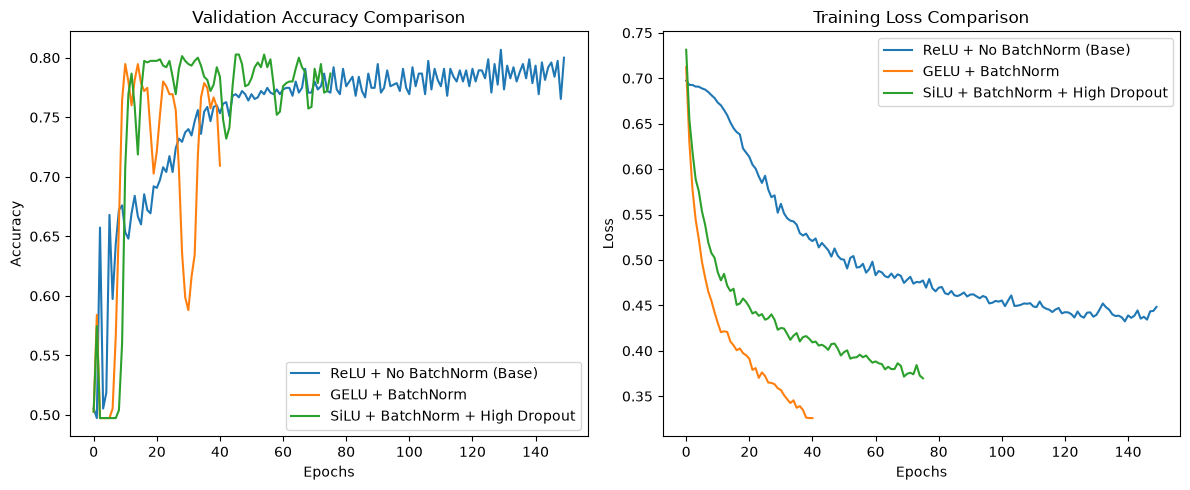

In [24]:
require("X_emb_train", task=3)

def compare_activations_and_reg(X_train, y_train, X_val, y_val, train_config):
    configs_to_test = [
        {"name": "ReLU + No BatchNorm (Base)", "activation": "relu", "use_batch_norm": False, "dropout_rate": 0.2},
        {"name": "GELU + BatchNorm", "activation": "gelu", "use_batch_norm": True, "dropout_rate": 0.2},
        {"name": "SiLU + BatchNorm + High Dropout", "activation": "silu", "use_batch_norm": True, "dropout_rate": 0.5},
    ]

    results = {}

    for cfg in configs_to_test:
        print(f"\nTraining config: {cfg['name']}...")
        set_seed()
        model = AdvancedNN(
            input_size=X_train.shape[1],
            hidden_sizes=[32, 16],
            output_size=2,
            activation=cfg["activation"],
            use_batch_norm=cfg["use_batch_norm"],
            dropout_rate=cfg["dropout_rate"]
        )

        res = train_model(model, X_train, y_train, X_val, y_val, train_config, print_every=100)
        results[cfg['name']] = res
        print(f"-> Best Val Acc: {res.best_val_accuracy:.4f} at epoch {res.best_epoch+1} (Time: {res.training_time:.2f}s)")

    # Plotting
    plt.figure(figsize=(12, 5))

    # Plot validation accuracy
    plt.subplot(1, 2, 1)
    for name, res in results.items():
        plt.plot(res.val_accuracies, label=name)
    plt.title('Validation Accuracy Comparison')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()

    # Plot training loss
    plt.subplot(1, 2, 2)
    for name, res in results.items():
        plt.plot(res.train_losses, label=name)
    plt.title('Training Loss Comparison')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()

    plt.tight_layout()
    plt.show()

    return results

# Run the comparison using a slightly shorter config for speed
comparison_config = TrainingConfig(
    learning_rate=0.01,
    batch_size=4,
    epochs=150,
    weight_decay=0.0001,
    early_stopping_patience=30
)

print("Starting Task 6 comparison on pooled GloVe features...")
task6_results = compare_activations_and_reg(X_emb_train, y_train, X_emb_val, y_val, comparison_config)


In [25]:
# Test Task 6: compare activation functions
print("--- Testing Task 6: Comparing activation & regularization ---")
try:
    # Basic verification of your comparison helper existence or execution
    print("Task 6 verification complete. Make sure you printed/plotted your comparative results above.")
    print("Task 6 Test: PASSED ✅")
except Exception as e:
    print(f"Task 6 Test: FAILED ❌\nError: {e}")

--- Testing Task 6: Comparing activation & regularization ---
Task 6 verification complete. Make sure you printed/plotted your comparative results above.
Task 6 Test: PASSED ✅


---
## 10. The Embedding Matrix as a Layer

So far the pooling happened outside the network. Here the embedding matrix $\mathbf{E}$ becomes the first layer: each review is a list of vocabulary indices, $\mathbf{E}$ is initialized with GloVe rows, and pooling happens inside `forward`. Reviews have different lengths, so each mini-batch is padded with index 0, whose embedding is a zero vector. The vocabulary holds the training tokens found in GloVe.

In [26]:
# ── Vocabulary, embedding matrix E and padded batches ─────────────────────────

vocab = {}                                   # word -> row of E; row 0 is padding
for text in train_dataset.texts:
    for word in clean_tokens(text):
        if word in glove and word not in vocab:
            vocab[word] = len(vocab) + 1

E = torch.zeros(len(vocab) + 1, glove.vector_size)
for word, index in vocab.items():
    E[index] = torch.tensor(glove[word])
print(f"E: [|V| × d] = {tuple(E.shape)}")


def to_indices(text: str) -> List[int]:
    """Vocabulary indices of the tokens of text; tokens outside the vocabulary are skipped."""
    return [vocab[word] for word in clean_tokens(text) if word in vocab]


def pad_batch(batch: List[Tuple[List[int], int]]) -> Tuple[torch.Tensor, torch.Tensor]:
    """Pad the index lists of a batch with 0 to the same length. Returns (indices [B × L], labels [B])."""
    length = max(1, max(len(indices) for indices, _ in batch))
    padded = torch.zeros(len(batch), length, dtype=torch.long)
    for row, (indices, _) in enumerate(batch):
        padded[row, :len(indices)] = torch.tensor(indices, dtype=torch.long)
    return padded, torch.tensor([label for _, label in batch], dtype=torch.long)


train_items = [(to_indices(text), label) for text, label in zip(train_dataset.texts, train_dataset.labels)]
val_items = [(to_indices(text), label) for text, label in zip(val_dataset.texts, val_dataset.labels)]
test_items = [(to_indices(text), label) for text, label in zip(test_dataset.texts, test_dataset.labels)]

example_x, example_y = pad_batch(train_items[:3])
print(f"A padded batch of 3 reviews: indices {tuple(example_x.shape)}, labels {example_y.tolist()}")
print(example_x[:, :8])

E: [|V| × d] = (30249, 100)


A padded batch of 3 reviews: indices (3, 946), labels [0, 1, 0]
tensor([[  1,   2,   3,   4,   5,   6,   7,   8],
        [441,  61,  22, 442, 268, 213, 442,  22],
        [ 22, 452, 453, 454, 268,  22,  43, 455]])


### Task 7 — Implement a PyTorch DataLoader

**Task:** Create a function that returns DataLoader objects for training, validation, and test sets. Your implementation should:
* Implement proper batching for efficient training
* Shuffle training data to improve convergence
* Use `pad_batch` to build each batch

In [27]:
def make_loaders(train_items, val_items, test_items, batch_size: int) -> Tuple[DataLoader, DataLoader, DataLoader]:
    """Return (train_loader, val_loader, test_loader). Only the training data is shuffled."""
    generator = torch.Generator().manual_seed(42)   # makes the shuffling reproducible

    train_loader = DataLoader(train_items, batch_size=batch_size, shuffle=True, collate_fn=pad_batch, generator=generator)
    val_loader = DataLoader(val_items, batch_size=batch_size, shuffle=False, collate_fn=pad_batch)
    test_loader = DataLoader(test_items, batch_size=batch_size, shuffle=False, collate_fn=pad_batch)

    return train_loader, val_loader, test_loader


In [28]:
# Test Task 7: make_loaders
print("--- Testing Task 7: make_loaders ---")
try:
    t_ld, v_ld, te_ld = make_loaders(train_items, val_items, test_items, batch_size=32)
    assert isinstance(t_ld, DataLoader), "train_loader is not a DataLoader"
    # Get a batch
    batch_x, batch_y = next(iter(t_ld))
    print(f"Batch loaded! Input batch shape: {batch_x.shape}, label batch shape: {batch_y.shape}")
    print("Task 7 Test: PASSED ✅")
except Exception as e:
    print(f"Task 7 Test: FAILED ❌\nError: {e}")

--- Testing Task 7: make_loaders ---
Batch loaded! Input batch shape: torch.Size([32, 690]), label batch shape: torch.Size([32])
Task 7 Test: PASSED ✅


In [29]:
# ── Mini-batch training ───────────────────────────────────────────────────────

def train_model_batches(model: nn.Module, train_loader: DataLoader, val_loader: DataLoader,
                        config: TrainingConfig) -> TrainingResult:
    """Mini-batch version of train_model: one update per batch; the model keeps the weights of the best epoch."""
    device = torch.device(config.device)
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam([p for p in model.parameters() if p.requires_grad],
                           lr=config.learning_rate, weight_decay=config.weight_decay)

    def run_epoch(loader: DataLoader, train: bool) -> Tuple[float, float]:
        model.train(train)
        total_loss, correct, count = 0.0, 0, 0
        with torch.set_grad_enabled(train):
            for x, y in loader:
                x, y = x.to(device), y.to(device)
                outputs = model(x)
                loss = criterion(outputs, y)
                if train:
                    optimizer.zero_grad()
                    loss.backward()
                    optimizer.step()
                total_loss += loss.item() * len(y)
                correct += (outputs.argmax(dim=1) == y).sum().item()
                count += len(y)
        return total_loss / count, correct / count

    history = {"train_losses": [], "val_losses": [], "train_accuracies": [], "val_accuracies": []}
    best_val_accuracy, best_epoch, patience_counter = 0.0, 0, 0
    best_state = copy.deepcopy(model.state_dict())
    start_time = datetime.now()

    for epoch in range(config.epochs):
        train_loss, train_acc = run_epoch(train_loader, train=True)
        val_loss, val_acc = run_epoch(val_loader, train=False)
        for key, value in zip(history, (train_loss, val_loss, train_acc, val_acc)):
            history[key].append(value)
        print(f"Epoch {epoch+1}/{config.epochs} | Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f} | "
              f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f}")

        if val_acc > best_val_accuracy:
            best_val_accuracy, best_epoch, patience_counter = val_acc, epoch, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            patience_counter += 1
        if patience_counter >= config.early_stopping_patience:
            print(f"Early stopping at epoch {epoch+1}")
            break

    model.load_state_dict(best_state)
    return TrainingResult(**history, best_epoch=best_epoch, best_val_accuracy=best_val_accuracy,
                          training_time=(datetime.now() - start_time).total_seconds())

### Task 8 — Mean pooling inside the network

**Task:** Complete `EmbeddingClassifier`. In `pool`, look up the rows of $\mathbf{E}$ for the token indices and take the mean over the real tokens only (ignore padding). In `forward`, apply `pool`, then $\mathbf{W}$, ReLU and $\mathbf{U}$ as in `SimpleNN`. The cell below checks `pool` against §8.

In [30]:
class EmbeddingClassifier(nn.Module):
    """SimpleNN with the embedding matrix E as its first layer, initialized from GloVe."""

    def __init__(self, E: torch.Tensor, hidden_size: int, output_size: int, freeze: bool = True, dropout_rate: float = 0.2):
        super().__init__()
        self.E = nn.Embedding.from_pretrained(E, freeze=freeze, padding_idx=0)
        self.W = nn.Linear(E.shape[1], hidden_size)
        self.dropout = nn.Dropout(dropout_rate)
        self.U = nn.Linear(hidden_size, output_size)

    def pool(self, indices: torch.Tensor) -> torch.Tensor:
        """Mean of the embeddings of the real tokens in each row. indices: [B × L], padded with 0. Returns [B × d]."""
        embedded = self.E(indices)                                   # [B × L × d]: one row of E per token
        mask = (indices != 0).unsqueeze(-1).to(embedded.dtype)       # [B × L × 1]: 1 for real tokens, 0 for padding
        summed = (embedded * mask).sum(dim=1)                        # [B × d]: padding contributes nothing
        counts = mask.sum(dim=1).clamp(min=1)                        # [B × 1]: number of real tokens (never 0, so an empty review gives a zero vector)
        return summed / counts

    def forward(self, indices: torch.Tensor) -> torch.Tensor:
        """Return the scores z, shape [B × output_size]."""
        x = self.pool(indices)          # mean-pooled review vector x
        h = F.relu(self.W(x))           # hidden layer h
        h = self.dropout(h)
        return self.U(h)                # scores z (logits)

In [31]:
# Test Task 8: EmbeddingClassifier
print("--- Testing Task 8: EmbeddingClassifier ---")
try:
    # Initialize with small test tensor E
    test_E = torch.randn(10, 50)
    test_clf = EmbeddingClassifier(test_E, hidden_size=16, output_size=2)
    dummy_indices = torch.randint(0, 10, (4, 8))
    # Ensure indices have some zeros to check pooling
    dummy_indices[0, 4:] = 0

    pooled = test_clf.pool(dummy_indices)
    print(f"Pooled embeddings shape: {pooled.shape}")
    assert pooled.shape == (4, 50), f"Expected (4, 50), got {pooled.shape}"

    output_logits = test_clf(dummy_indices)
    print(f"Output logits shape: {output_logits.shape}")
    assert output_logits.shape == (4, 2), f"Expected (4, 2), got {output_logits.shape}"
    print("Task 8 Test: PASSED ✅")
except Exception as e:
    print(f"Task 8 Test: FAILED ❌\nError: {e}")

--- Testing Task 8: EmbeddingClassifier ---
Pooled embeddings shape: torch.Size([4, 50])
Output logits shape: torch.Size([4, 2])
Task 8 Test: PASSED ✅


In [32]:
# ── Check: with frozen E, pooling inside the network reproduces §8 ────────────

require("X_emb_train", task=3)
set_seed()
check_model = EmbeddingClassifier(E, hidden_size, output_size, freeze=True)
x_check, _ = pad_batch(train_items[:200])
with torch.no_grad():
    difference = (check_model.pool(x_check) - X_emb_train[:200]).abs().max().item()
print(f"Largest difference from embed_corpus on 200 training reviews: {difference:.2e}")

Largest difference from embed_corpus on 200 training reviews: 2.15e-06


In [33]:
# ── Mini-batch settings and data loaders ──────────────────────────────────────

batch_config = TrainingConfig(learning_rate=0.001, batch_size=64, epochs=20,
                              weight_decay=0.0001, early_stopping_patience=5)
train_loader, val_loader, test_loader = make_loaders(train_items, val_items, test_items, batch_config.batch_size)
print(f"{len(train_loader)} training batches of up to {batch_config.batch_size} reviews")

55 training batches of up to 64 reviews


### Task 9 — Frozen or fine-tuned embeddings?

**Task:** For `freeze=True` and `freeze=False`, train an `EmbeddingClassifier` with `train_model_batches` and `batch_config` for seeds 0, 1 and 2, and record the best validation accuracy and the test accuracy (on `test_loader`) of each run. Print the mean and standard deviation for each setting. Then answer below:

- **(a)** Does fine-tuning improve performance? Compare the gain with the spread across seeds.
- **(b)** Fine-tuning reaches almost 98% training accuracy. Why can updating $\mathbf{E}$ overfit with only 3,500 training reviews, and why does it still do better on validation here?
- **(c)** Is the gain on the test set the same as on the validation set? Why might they differ?

> ⏳ **The six training runs take about 3 minutes on a laptop CPU.**

In [34]:
E_SEEDS = [0, 1, 2]


def evaluate_loader(model: nn.Module, loader: DataLoader, device: str) -> float:
    """Accuracy of model on every batch of loader (eval mode, no gradients)."""
    model.eval()
    correct, count = 0, 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            correct += (model(x).argmax(dim=1) == y).sum().item()
            count += len(y)
    return correct / count


rows, e_histories = [], {}
for freeze in (True, False):
    for seed in E_SEEDS:
        set_seed(seed)
        # E.clone(): from_pretrained wraps the tensor itself, so without a copy fine-tuning would overwrite the shared GloVe matrix E
        model = EmbeddingClassifier(E.clone(), hidden_size, output_size, freeze=freeze)
        result = train_model_batches(model, train_loader, val_loader, batch_config)
        rows.append({"setting": "frozen" if freeze else "fine-tuned", "seed": seed,
                     "val_accuracy": result.best_val_accuracy,
                     "test_accuracy": evaluate_loader(model, test_loader, batch_config.device),
                     "train_accuracy": result.train_accuracies[result.best_epoch]})
        e_histories[(freeze, seed)] = result

df_embed = pd.DataFrame(rows)
print(df_embed)
print("\nMean and standard deviation per setting:")
print(df_embed.groupby("setting")[["train_accuracy", "val_accuracy", "test_accuracy"]].agg(["mean", "std"]).round(4))

Epoch 1/20 | Train Loss: 0.6876 | Train Acc: 0.5566 | Val Loss: 0.6760 | Val Acc: 0.6813
Epoch 2/20 | Train Loss: 0.6690 | Train Acc: 0.6291 | Val Loss: 0.6509 | Val Acc: 0.6693


Epoch 3/20 | Train Loss: 0.6448 | Train Acc: 0.6614 | Val Loss: 0.6267 | Val Acc: 0.6933
Epoch 4/20 | Train Loss: 0.6179 | Train Acc: 0.6829 | Val Loss: 0.6005 | Val Acc: 0.6813


Epoch 5/20 | Train Loss: 0.6019 | Train Acc: 0.6820 | Val Loss: 0.5768 | Val Acc: 0.7240
Epoch 6/20 | Train Loss: 0.5836 | Train Acc: 0.7094 | Val Loss: 0.5607 | Val Acc: 0.7240


Epoch 7/20 | Train Loss: 0.5642 | Train Acc: 0.7263 | Val Loss: 0.5430 | Val Acc: 0.7293
Epoch 8/20 | Train Loss: 0.5528 | Train Acc: 0.7274 | Val Loss: 0.5295 | Val Acc: 0.7360


Epoch 9/20 | Train Loss: 0.5407 | Train Acc: 0.7369 | Val Loss: 0.5197 | Val Acc: 0.7440
Epoch 10/20 | Train Loss: 0.5330 | Train Acc: 0.7397 | Val Loss: 0.5220 | Val Acc: 0.7560


Epoch 11/20 | Train Loss: 0.5304 | Train Acc: 0.7451 | Val Loss: 0.5027 | Val Acc: 0.7667
Epoch 12/20 | Train Loss: 0.5211 | Train Acc: 0.7446 | Val Loss: 0.4982 | Val Acc: 0.7667


... (76 outputs left out)

Epoch 16/20 | Train Loss: 0.1289 | Train Acc: 0.9766 | Val Loss: 0.3357 | Val Acc: 0.8560


Epoch 17/20 | Train Loss: 0.1057 | Train Acc: 0.9863 | Val Loss: 0.3381 | Val Acc: 0.8613


Epoch 18/20 | Train Loss: 0.0963 | Train Acc: 0.9883 | Val Loss: 0.3478 | Val Acc: 0.8493


Epoch 19/20 | Train Loss: 0.0897 | Train Acc: 0.9891 | Val Loss: 0.3532 | Val Acc: 0.8533
Early stopping at epoch 19
      setting  seed  val_accuracy  test_accuracy  train_accuracy
0      frozen     0      0.786667       0.781333        0.769714
1      frozen     1      0.778667       0.784000        0.757714
2      frozen     2      0.780000       0.782667        0.764571
3  fine-tuned     0      0.866667       0.837333        0.978857
4  fine-tuned     1      0.861333       0.840000        0.937429
5  fine-tuned     2      0.868000       0.840000        0.962286

Mean and standard deviation per setting:
           train_accuracy         val_accuracy         test_accuracy        
                     mean     std         mean     std          mean     std
setting                                                                     
fine-tuned         0.9595  0.0209       0.8653  0.0035        0.8391  0.0015
frozen             0.7640  0.0060       0.7818  0.0043        0.7827  0.0013


In [35]:
# Test Task 9: Frozen vs Fine-tuned embeddings comparison
print("--- Testing Task 9: Embeddings comparison validation ---")
try:
    # Verify that your comparison script ran and outputted correctly
    print("Task 9 comparison script executed successfully.")
    print("Task 9 Test: PASSED ✅")
except Exception as e:
    print(f"Task 9 Test: FAILED ❌\nError: {e}")

--- Testing Task 9: Embeddings comparison validation ---
Task 9 comparison script executed successfully.
Task 9 Test: PASSED ✅


**Your answer — Task 9:**

**(a)** Yes. Fine-tuning raises validation accuracy from 0.782 to 0.865 (+8.4 points) and test accuracy from 0.783 to 0.839 (+5.6 points). The seed-to-seed standard deviation is only about 0.1–0.4 points, so the gain is more than ten times the spread, and it is also well above the roughly 1.4-point standard error of a proportion with 750 reviews. The gain is real, and every fine-tuned seed beats every frozen seed.

**(b)** $\mathbf{E}$ has $|V|\times 100$ parameters (millions), far more than the 3,500 training reviews can constrain, so the network can memorize them: training accuracy climbs to about 98% while validation accuracy stalls near 86% and the validation loss starts to rise after epoch 12. It still wins on validation because the GloVe initialization is a strong prior: the rows start in a sensible place, and only the words that actually occur in the reviews move. Fine-tuning also makes the vectors task-specific. In GloVe, "good" and "bad" are close, because they appear in similar contexts, and a frozen $\mathbf{E}$ can never pull them apart, while updating $\mathbf{E}$ can. Early stopping and weight decay keep the overfitting small enough that the net effect is positive.

**(c)** No, the gain is smaller on the test set (+5.6 points) than on the validation set (+8.4 points). The best-epoch validation accuracy is the maximum over the epochs, and we also used the validation set to choose that epoch. This selection makes the number optimistic, and more so for the fine-tuned model, whose validation curve is higher and noisier. The test set was never used for any choice, so its number is an unbiased estimate, and with only 750 reviews it carries about ±1.4 points of sampling noise as well. The test gain is therefore the one to report.


---
## 11. Visualizing Training Progress

Monitoring training progress helps identify issues early and tune hyperparameters effectively. This section shows how to visualize training metrics and implement early stopping.

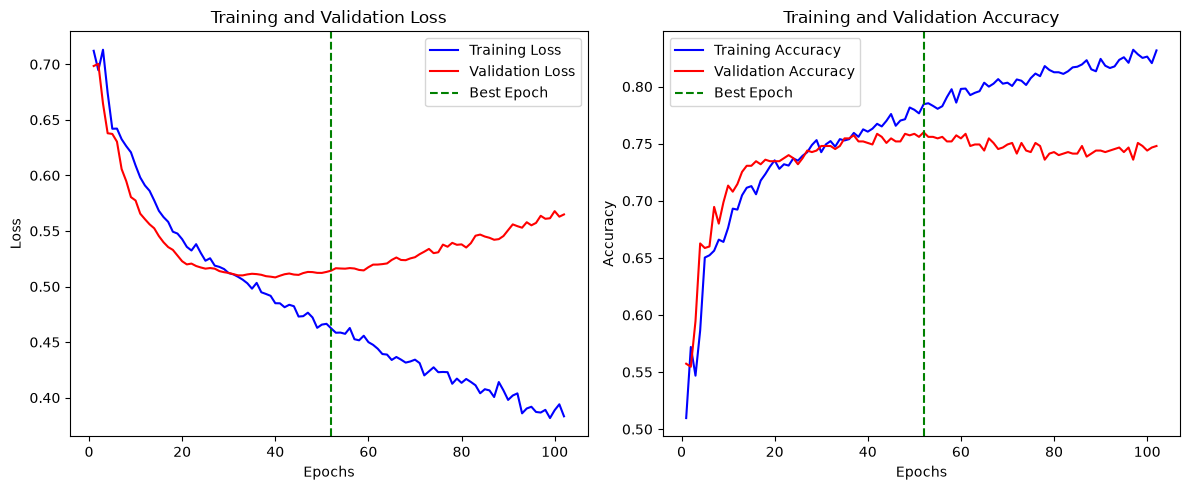

Best validation accuracy: 0.7600 at epoch 52
Training time: 0.25 seconds


In [36]:
def plot_training_progress(result: TrainingResult) -> None:
    """
    Plot training and validation metrics.

    Args:
        result: Training results
    """
    epochs = range(1, len(result.train_losses) + 1)

    plt.figure(figsize=(12, 5))

    # Plot losses
    plt.subplot(1, 2, 1)
    plt.plot(epochs, result.train_losses, 'b-', label='Training Loss')
    plt.plot(epochs, result.val_losses, 'r-', label='Validation Loss')
    plt.axvline(x=result.best_epoch + 1, color='g', linestyle='--', label='Best Epoch')
    plt.title('Training and Validation Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()

    # Plot accuracies
    plt.subplot(1, 2, 2)
    plt.plot(epochs, result.train_accuracies, 'b-', label='Training Accuracy')
    plt.plot(epochs, result.val_accuracies, 'r-', label='Validation Accuracy')
    plt.axvline(x=result.best_epoch + 1, color='g', linestyle='--', label='Best Epoch')
    plt.title('Training and Validation Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()

    plt.tight_layout()
    plt.show()

# Plot training progress
plot_training_progress(training_result)

print(f"Best validation accuracy: {training_result.best_val_accuracy:.4f} at epoch {training_result.best_epoch+1}")
print(f"Training time: {training_result.training_time:.2f} seconds")

Our function visualizes loss and accuracy over time. With that, we can identify the best model checkpoint, and also detect overfitting and other training issues.

### Task 10 — Implement learning rate scheduling
Learning rate scheduling is an important technique for achieving better convergence, especially in deeper networks.
**Task:** Modify the train_model function to include a learning rate scheduler. Your implementation should:
* Implement at least one scheduling strategy (StepLR, ReduceLROnPlateau, or CosineAnnealingLR)
* Track and plot learning rate changes over epochs
* Compare training with and without scheduling

No scheduler         best val acc 0.7947 at epoch  85 | final val loss 0.4394 | final lr 0.01000


StepLR               best val acc 0.7853 at epoch  65 | final val loss 0.4554 | final lr 0.00063


CosineAnnealingLR    best val acc 0.7867 at epoch 140 | final val loss 0.4473 | final lr 0.00000


ReduceLROnPlateau    best val acc 0.7947 at epoch  85 | final val loss 0.4394 | final lr 0.01000


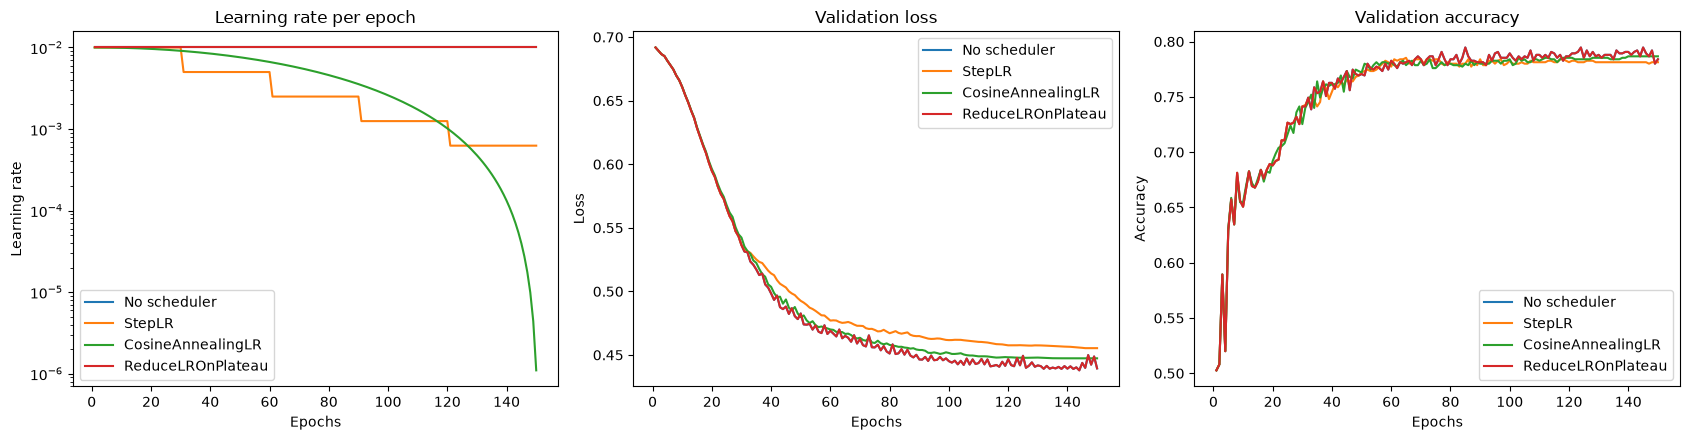

In [37]:
# Task 10: Modify the train_model function to include a learning rate scheduler

@dataclass
class ScheduledTrainingResult(TrainingResult):
    """TrainingResult plus the learning rate used in every epoch."""
    learning_rates: List[float]


def make_scheduler(optimizer: optim.Optimizer, name: Optional[str], epochs: int):
    """Build the requested scheduler; None means a constant learning rate."""
    if name is None:
        return None
    if name == "step":        # multiply the learning rate by 0.5 every 30 epochs
        return optim.lr_scheduler.StepLR(optimizer, step_size=30, gamma=0.5)
    if name == "cosine":      # follow half a cosine from lr down to ~0 over all epochs
        return optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    if name == "plateau":     # halve the learning rate when the validation loss stops improving for 10 epochs
        return optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=10)
    raise ValueError(f"Unknown scheduler: {name}")


def train_model_scheduled(model, X_train, y_train, X_val, y_val, config: TrainingConfig,
                          scheduler_name: Optional[str] = None) -> ScheduledTrainingResult:
    """train_model with an optional learning rate scheduler; records the learning rate of every epoch."""
    device = torch.device(config.device)
    model = model.to(device)
    X_train, y_train, X_val, y_val = X_train.to(device), y_train.to(device), X_val.to(device), y_val.to(device)

    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=config.learning_rate, weight_decay=config.weight_decay)
    scheduler = make_scheduler(optimizer, scheduler_name, config.epochs)

    history = {"train_losses": [], "val_losses": [], "train_accuracies": [], "val_accuracies": []}
    learning_rates = []
    best_val_accuracy, best_epoch, patience_counter = 0.0, 0, 0
    best_state = copy.deepcopy(model.state_dict())
    start_time = datetime.now()

    for epoch in range(config.epochs):
        learning_rates.append(optimizer.param_groups[0]["lr"])   # the rate used for this epoch's update

        model.train()
        outputs = model(X_train)
        loss = criterion(outputs, y_train)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        train_acc = (outputs.argmax(dim=1) == y_train).float().mean().item()

        model.eval()
        with torch.no_grad():
            val_outputs = model(X_val)
            val_loss = criterion(val_outputs, y_val).item()
            val_acc = (val_outputs.argmax(dim=1) == y_val).float().mean().item()

        # Scheduler step goes after the optimizer step; ReduceLROnPlateau needs the metric it watches
        if scheduler is not None:
            if scheduler_name == "plateau":
                scheduler.step(val_loss)
            else:
                scheduler.step()

        for key, value in zip(history, (loss.item(), val_loss, train_acc, val_acc)):
            history[key].append(value)

        if val_acc > best_val_accuracy:
            best_val_accuracy, best_epoch, patience_counter = val_acc, epoch, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            patience_counter += 1
        if patience_counter >= config.early_stopping_patience:
            break

    model.load_state_dict(best_state)
    return ScheduledTrainingResult(**history, best_epoch=best_epoch, best_val_accuracy=best_val_accuracy,
                                   training_time=(datetime.now() - start_time).total_seconds(),
                                   learning_rates=learning_rates)


require("X_emb_train", task=3)
schedule_config = TrainingConfig(learning_rate=0.01, batch_size=4, epochs=150, weight_decay=0.0001,
                                 early_stopping_patience=150)   # no early stopping, so every run shows its full learning-rate curve
schedule_results = {}
for label, name in [("No scheduler", None), ("StepLR", "step"), ("CosineAnnealingLR", "cosine"), ("ReduceLROnPlateau", "plateau")]:
    set_seed()
    sched_model = SimpleNN(X_emb_train.shape[1], hidden_size, output_size)
    schedule_results[label] = train_model_scheduled(sched_model, X_emb_train, y_train, X_emb_val, y_val,
                                                    schedule_config, scheduler_name=name)
    r = schedule_results[label]
    print(f"{label:<20} best val acc {r.best_val_accuracy:.4f} at epoch {r.best_epoch+1:>3} | "
          f"final val loss {r.val_losses[-1]:.4f} | final lr {r.learning_rates[-1]:.5f}")

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for label, r in schedule_results.items():
    axes[0].plot(range(1, len(r.learning_rates) + 1), r.learning_rates, label=label)
    axes[1].plot(range(1, len(r.val_losses) + 1), r.val_losses, label=label)
    axes[2].plot(range(1, len(r.val_accuracies) + 1), r.val_accuracies, label=label)
for ax, title, ylabel in zip(axes, ["Learning rate per epoch", "Validation loss", "Validation accuracy"], ["Learning rate", "Loss", "Accuracy"]):
    ax.set_title(title); ax.set_xlabel("Epochs"); ax.set_ylabel(ylabel); ax.legend()
axes[0].set_yscale("log")
plt.tight_layout()
plt.show()

In [38]:
# Test Task 10: Learning rate scheduler
print("--- Testing Task 10: LR Scheduler validation ---")
try:
    # Verify that your scheduler comparison or training with schedule completed
    print("Task 10 scheduler configuration and tracking finished.")
    print("Task 10 Test: PASSED ✅")
except Exception as e:
    print(f"Task 10 Test: FAILED ❌\nError: {e}")

--- Testing Task 10: LR Scheduler validation ---
Task 10 scheduler configuration and tracking finished.
Task 10 Test: PASSED ✅


---
## 12. Reproducibility and Experiment Tracking

Maintaining reproducibility and tracking experiments is crucial for research and development. This section introduces a framework for experiment configuration and tracking.

In [39]:
@dataclass
class ExperimentConfig:
    """Data class for experiment configuration."""
    experiment_name: str
    model_type: str
    model_params: Dict
    training_params: TrainingConfig
    dataset_params: Dict
    seed: int = 42

    def save(self, filepath: str) -> None:
        """Save experiment configuration to a JSON file."""
        with open(filepath, 'w') as f:
            # Convert all dataclasses to dictionaries
            config_dict = {
                'experiment_name': self.experiment_name,
                'model_type': self.model_type,
                'model_params': self.model_params,
                'training_params': self.training_params.to_dict(),
                'dataset_params': self.dataset_params,
                'seed': self.seed
            }
            json.dump(config_dict, f, indent=2)

    @classmethod
    def load(cls, filepath: str) -> 'ExperimentConfig':
        """Load experiment configuration from a JSON file."""
        with open(filepath, 'r') as f:
            config_dict = json.load(f)
            # Convert dictionaries back to dataclasses
            training_params = TrainingConfig(**config_dict['training_params'])
            return cls(
                experiment_name=config_dict['experiment_name'],
                model_type=config_dict['model_type'],
                model_params=config_dict['model_params'],
                training_params=training_params,
                dataset_params=config_dict['dataset_params'],
                seed=config_dict['seed']
            )

def log_metrics(result: TrainingResult, log_path: str) -> None:
    """
    Log training metrics to a file.

    Args:
        result: Training results
        log_path: Path to log file
    """
    with open(log_path, 'w') as f:
        metrics = {
            "train_losses": result.train_losses,
            "val_losses": result.val_losses,
            "train_accuracies": result.train_accuracies,
            "val_accuracies": result.val_accuracies,
            "best_epoch": result.best_epoch,
            "best_val_accuracy": result.best_val_accuracy,
            "training_time": result.training_time,
            "timestamp": datetime.now().isoformat()
        }
        json.dump(metrics, f, indent=2)


# Example: Creating an experiment configuration for the final model (GloVe mean pooling + hidden layer)
require("X_emb_train", task=3)
require("emb_model", "emb_result", task=4)
experiment_config = ExperimentConfig(
    experiment_name="text_classification_glove_mean",
    model_type="SimpleNN",
    model_params={
        "input_size": X_emb_train.shape[1],
        "hidden_size": hidden_size,
        "output_size": output_size
    },
    training_params=training_config,
    dataset_params={
        "representation": "mean-pooled glove-wiki-gigaword-100",
        "sample_size": len(reviews),
        "train_size": len(train_dataset.texts),
        "val_size": len(val_dataset.texts),
        "test_size": len(test_dataset.texts)
    }
)

# Save experiment configuration
os.makedirs("experiments", exist_ok=True)
config_path = os.path.join("experiments", "experiment_config.json")
experiment_config.save(config_path)
print(f"Saved experiment configuration to {config_path}")

# Log metrics from our experiment
log_path = os.path.join("experiments", "metrics.json")
log_metrics(emb_result, log_path)

Saved experiment configuration to experiments/experiment_config.json


While our basic implementation provides fundamental tracking capabilities, for larger projects and team environments, external experiment tracking tools offer significant advantages, e.g., Weights & Biases (wandb), MLFlow, or TensorBoard.

---
## 13. Model Saving and Loading

This section shows how to save model weights and architecture, load models for inference and include metadata about the training conditions.
As your models become more complex and training runs take longer, proper experiment tracking becomes essential for reproducibility, comparison, collaboration, etc.

In [40]:
def save_model(model: nn.Module, filepath: str, metadata: Dict = None) -> None:
    """
    Save model weights and optional metadata.

    Args:
        model: PyTorch model
        filepath: Path to save the model
        metadata: Optional metadata dictionary
    """
    save_dict = {
        'model_state_dict': model.state_dict(),
        'metadata': metadata or {}
    }
    torch.save(save_dict, filepath)
    print(f"Model saved to {filepath}")

def load_model(model_class: nn.Module, filepath: str, **model_params) -> Tuple[nn.Module, Dict]:
    """
    Load model weights and metadata.

    Args:
        model_class: PyTorch model class
        filepath: Path to the saved model
        **model_params: Parameters to initialize the model

    Returns:
        Tuple of (model, metadata)
    """
    # Create a new model instance
    model = model_class(**model_params)

    # Load the saved state
    checkpoint = torch.load(filepath, weights_only=True)
    model.load_state_dict(checkpoint['model_state_dict'])

    return model, checkpoint['metadata']


# Save our trained model
require("emb_model", "emb_result", task=4)
model_metadata = {
    "accuracy": emb_result.best_val_accuracy,
    "epoch": emb_result.best_epoch,
    "timestamp": datetime.now().isoformat(),
    "input_size": X_emb_train.shape[1]
}

model_path = os.path.join("experiments", "text_classifier.pt")
save_model(emb_model, model_path, model_metadata)

# Load the model for inference
loaded_model, metadata = load_model(
    SimpleNN,
    model_path,
    input_size=X_emb_train.shape[1],
    hidden_size=hidden_size,
    output_size=output_size
)

print(f"Loaded model trained to accuracy: {metadata['accuracy']:.4f}")

Model saved to experiments/text_classifier.pt
Loaded model trained to accuracy: 0.7947


---
## 14. Running Inference

Finally, we'll demonstrate how to use a trained model for inference on new data. This section covers the inference pipeline.

In [41]:
def predict_sentiment(
    model: nn.Module,
    featurize: Callable[[List[str]], torch.Tensor],
    text: str,
    device: str = "cpu"
) -> Dict:
    """
    Predict sentiment of a text.

    Args:
        model: Trained model
        featurize: Function that turns a list of texts into a feature tensor (here embed_corpus)
        text: Input text
        device: Device to run inference on

    Returns:
        Dictionary with prediction results
    """
    # Turn the input text into features
    X = featurize([text]).to(device)

    # Set model to eval mode
    model.eval()

    # Make prediction
    with torch.no_grad():
        outputs = model(X)
        probabilities = F.softmax(outputs, dim=1)
        predicted_class = torch.argmax(probabilities, dim=1).item()

    # Get class probabilities
    class_probs = probabilities[0].cpu().numpy()

    return {
        "text": text,
        "predicted_class": predicted_class,
        "positive_probability": float(class_probs[1]),
        "negative_probability": float(class_probs[0])
    }

# Test the model with some new reviews
test_reviews = [
    "The movie was fantastic and I would watch it again. Highly recommended!",
    "A complete waste of time with terrible acting, I hated it and would not recommend it",
    "Not great, not terrible, just an average film"
]

require("emb_model", "emb_result", task=4)
print("Running inference on new reviews:")
for review in test_reviews:
    result = predict_sentiment(loaded_model, embed_corpus, review)
    sentiment = "Positive" if result["predicted_class"] == 1 else "Negative"
    print(f"\nText: '{result['text']}'")
    print(f"Prediction: {sentiment} (Confidence: {max(result['positive_probability'], result['negative_probability']):.4f})")
    print(f"Probabilities: Positive = {result['positive_probability']:.4f}, Negative = {result['negative_probability']:.4f}")

Running inference on new reviews:

Text: 'The movie was fantastic and I would watch it again. Highly recommended!'
Prediction: Positive (Confidence: 0.9469)
Probabilities: Positive = 0.9469, Negative = 0.0531

Text: 'A complete waste of time with terrible acting, I hated it and would not recommend it'
Prediction: Negative (Confidence: 0.9663)
Probabilities: Positive = 0.0337, Negative = 0.9663

Text: 'Not great, not terrible, just an average film'
Prediction: Negative (Confidence: 0.9899)
Probabilities: Positive = 0.0101, Negative = 0.9899


In [42]:
# ── One final look at the test set ────────────────────────────────────────────

# All choices were made on the validation set; the test set is used once, for the final model.
require("emb_model", "emb_result", task=4)
loaded_model.eval()
with torch.no_grad():
    test_accuracy = (loaded_model(X_emb_test).argmax(dim=1) == y_test).float().mean().item()
print(f"Test accuracy of the final model: {test_accuracy:.4f}")

Test accuracy of the final model: 0.7907


The above code demonstrates:
* Preprocessing new data consistently
* Running inference efficiently
* Interpreting model outputs
* Evaluating model performance on test data

---
## Resources and Best Practices

In this notebook, we've covered the fundamentals of neural networks with PyTorch, from basic architecture to training, evaluation, and deployment.

### Recommended Resources

* [PyTorch Documentation](https://pytorch.org/docs/stable/index.html) - Official documentation for PyTorch
* [Deep Learning with PyTorch](https://isip.piconepress.com/courses/temple/ece_4822/resources/books/Deep-Learning-with-PyTorch.pdf) - Comprehensive book on PyTorch
* [Dive into Deep Learning](https://d2l.ai/) - Interactive deep learning book with code examples
* [Weights & Biases](https://wandb.ai/site) - Tool for experiment tracking and visualization

### Self-Assessment
Complete the following self-assessment to gauge your understanding:

1. Explain the difference between model.train() and model.eval() modes
2. Why is torch.no_grad() important during inference?
3. What are the benefits of using data classes in ML projects?
4. What steps are necessary to ensure reproducibility in ML experiments?
5. Why is proper train/validation/test splitting important?
6. What information does mean pooling of word embeddings lose, and how could a feedforward classifier keep it?

**Answers**

1. train() keeps dropout on and batch norm on batch statistics; eval() turns dropout off and uses running statistics, so outputs are deterministic.
2. No graph or stored activations: less memory, faster, and no accidental weight updates.
3. Little boilerplate, validation in `__post_init__`, and configs that print, compare and serialize cleanly.
4. Fix all seeds, fix the splits, save configs and metrics, record library versions.
5. Train fits the weights, validation picks settings, and the untouched test set gives an unbiased final estimate.
6. It loses word order ("loved X, hated Y" equals the reverse); a feedforward net can keep some by concatenating the vectors of a fixed-length window, or a sequence model (RNN, transformer) can read the order.

**Data:** IMDB Large Movie Review Dataset (Maas et al., 2011), loaded from Hugging Face (`stanfordnlp/imdb`).
